# FinSight AI - Notebook 3: SFT + DPO

**Goal:** Continue training **Checkpoint 1 (DAPT)** into:

`Checkpoint 1 → SFT → Checkpoint 2 → DPO → Checkpoint 3`

This notebook directly loads the synthetic SFT and DPO datasets created for FinSight AI, performs EDA, trains with QLoRA/LoRA, evaluates training/evaluation losses, and saves Checkpoints 2 and 3.

### Training stages

1. Load Checkpoint 1 from Notebook 2
2. Load the synthetic financial instruction dataset
3. Perform SFT dataset EDA
4. Split SFT data into train/evaluation sets
5. Continue training from Checkpoint 1 with SFT
6. Save **Checkpoint 2**
7. Load the synthetic preference dataset
8. Perform DPO dataset EDA
9. Split DPO data into train/evaluation sets
10. Continue training from Checkpoint 2 with DPO
11. Save **Checkpoint 3**
12. Run generation-based sanity checks on held-out prompts

> **Important:** This is a portfolio demonstration using a small synthetic corpus. The resulting metrics are useful for demonstrating the post-training workflow, not for claiming production or state-of-the-art performance.


## 1. Install dependencies

Run this notebook in **Google Colab with a GPU runtime**.

The notebook uses:
- Hugging Face Transformers
- TRL for SFT and DPO
- PEFT for LoRA adapters
- Unsloth for memory-efficient 4-bit loading
- BitsAndBytes for QLoRA


In [1]:
!pip -q install -U unsloth trl transformers datasets accelerate peft bitsandbytes sentencepiece

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.1/81.1 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.3/24.3 MB 58.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 kB 37.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 89.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.8/506.8 kB 43.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 38.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 832.9/832.9 kB 60.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 19.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.7/119.7 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 199.3/199.3 kB 22.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## 2. Imports, reproducibility, and GPU check

In [2]:
import gc
import json
import math
import os
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

assert torch.cuda.is_available(), "Enable a GPU runtime in Colab."

print("GPU:", torch.cuda.get_device_name(0))
print("CUDA:", torch.version.cuda)
print("PyTorch:", torch.__version__)


GPU: Tesla T4
CUDA: 12.8
PyTorch: 2.11.0+cu128


## 3. Configure paths

If you are running this immediately after Notebook 2 in the **same Colab runtime**, the Checkpoint 1 files should already exist.

The dataset ZIP can be uploaded/extracted into `/content/finsight_notebook3`.

If you start a fresh Colab runtime, upload:
- `FinSight_Notebook3_Datasets.zip`
- the `/content/finsight_dapt/` directory produced by Notebook 2, or its Checkpoint 1 adapter and manifest

The code below supports either the standard paths or a manual path override.


In [3]:
# Standard project locations
DATA_DIR = Path("/content/FinSight_Notebook3_Datasets_Instructional_and_Preference")
WORK_DIR = Path("/content/FinSight_post_training")
DAPT_DIR = Path("/content/FinSight_dapt_Checkpoint_1")

DATA_DIR.mkdir(parents=True, exist_ok=True)
WORK_DIR.mkdir(parents=True, exist_ok=True)

SFT_FILE = DATA_DIR / "finsight_sft_financial_instructions_200.jsonl"
DPO_FILE = DATA_DIR / "finsight_dpo_preference_100.jsonl"

CHECKPOINT_1_MANIFEST = DAPT_DIR / "checkpoint_1_manifest.json"

print("SFT:", SFT_FILE)
print("DPO:", DPO_FILE)
print("Checkpoint 1 manifest:", CHECKPOINT_1_MANIFEST)


SFT: /content/FinSight_Notebook3_Datasets_Instructional_and_Preference/finsight_sft_financial_instructions_200.jsonl
DPO: /content/FinSight_Notebook3_Datasets_Instructional_and_Preference/finsight_dpo_preference_100.jsonl
Checkpoint 1 manifest: /content/FinSight_dapt_Checkpoint_1/checkpoint_1_manifest.json


### If the dataset ZIP is not extracted yet

Upload `FinSight_Notebook3_Datasets.zip` using the Colab file browser, then run the next cell. It automatically extracts the ZIP and locates the JSONL files.


In [4]:
# Optional automatic ZIP extraction
from pathlib import Path
import zipfile

zip_candidates = list(Path("/content").glob("FinSight_Notebook3_Datasets*.zip"))

if zip_candidates:
    zip_path = zip_candidates[0]
    extract_root = Path("/content/finsight_notebook3")
    extract_root.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_root)

    # The ZIP may contain a top-level directory.
    matches = list(extract_root.rglob("finsight_sft_financial_instructions_200.jsonl"))
    if matches:
        SFT_FILE = matches[0]
        DPO_FILE = matches[0].parent / "finsight_dpo_preference_100.jsonl"

print("SFT file:", SFT_FILE)
print("DPO file:", DPO_FILE)
print("SFT exists:", SFT_FILE.exists())
print("DPO exists:", DPO_FILE.exists())


SFT file: /content/FinSight_Notebook3_Datasets_Instructional_and_Preference/finsight_sft_financial_instructions_200.jsonl
DPO file: /content/FinSight_Notebook3_Datasets_Instructional_and_Preference/finsight_dpo_preference_100.jsonl
SFT exists: True
DPO exists: True


## 4. Load Checkpoint 1

Notebook 2 stores Checkpoint 1 as a **LoRA adapter**, not as a full model copy.

The manifest tells Notebook 3:
- which base model was selected
- where its adapter was saved
- which validation perplexity was obtained

If the manifest is unavailable, set `BASE_MODEL_OVERRIDE` and `CHECKPOINT_1_ADAPTER_OVERRIDE` manually.


In [5]:
BASE_MODEL_OVERRIDE = None
CHECKPOINT_1_ADAPTER_OVERRIDE = "/content/FinSight_dapt_Checkpoint_1/Models/mistral_7b/checkpoint_1_adapter"

if CHECKPOINT_1_MANIFEST.exists():
    checkpoint_1 = json.loads(CHECKPOINT_1_MANIFEST.read_text())
    BASE_MODEL = checkpoint_1["base_model"]
    CHECKPOINT_1_ADAPTER = Path(checkpoint_1["adapter_path"])
    print(json.dumps(checkpoint_1, indent=2))
else:
    if BASE_MODEL_OVERRIDE is None or CHECKPOINT_1_ADAPTER_OVERRIDE is None:
        raise FileNotFoundError(
            "Checkpoint 1 manifest was not found. Run Notebook 2 first, "
            "or set BASE_MODEL_OVERRIDE and CHECKPOINT_1_ADAPTER_OVERRIDE."
        )
    BASE_MODEL = BASE_MODEL_OVERRIDE
    CHECKPOINT_1_ADAPTER = "/content/FinSight_dapt_Checkpoint_1/Models/mistral_7b/checkpoint_1_adapter"

assert CHECKPOINT_1_ADAPTER.exists(), f"Checkpoint 1 adapter not found: {CHECKPOINT_1_ADAPTER}"
print("Base model:", BASE_MODEL)
print("Checkpoint 1 adapter:", CHECKPOINT_1_ADAPTER)


{
  "checkpoint": "checkpoint_1",
  "model_key": "mistral_7b",
  "base_model": "mistralai/Mistral-7B-v0.3",
  "adapter_path": "/content/FinSight_dapt_Checkpoint_1/models/mistral_7b/checkpoint_1_adapter",
  "validation_perplexity": 5.270730562705297,
  "selection_method": "lowest validation perplexity on held-out DAPT corpus",
  "note": "Provisional selection; confirm with independent financial benchmark evaluation."
}
Base model: mistralai/Mistral-7B-v0.3
Checkpoint 1 adapter: /content/FinSight_dapt_Checkpoint_1/models/mistral_7b/checkpoint_1_adapter


## 5. Notebook 3 training configuration

These settings are intentionally conservative for Colab.

The sequence is:

`Checkpoint 1 adapter → SFT continuation → Checkpoint 2 adapter → DPO continuation → Checkpoint 3 adapter`

We do **not** merge checkpoints into a separate full model during training. The LoRA adapter is continued from the previous checkpoint.


In [6]:
CFG = {
    "max_seq_length": 1024,

    # QLoRA loading
    "load_in_4bit": True,

    # SFT
    "sft_epochs": 2,
    "sft_learning_rate": 1e-4,
    "sft_batch_size": 1,
    "sft_gradient_accumulation_steps": 8,
    "sft_warmup_ratio": 0.05,

    # DPO
    "dpo_epochs": 1,
    "dpo_learning_rate": 5e-5,
    "dpo_batch_size": 1,
    "dpo_gradient_accumulation_steps": 8,
    "dpo_warmup_ratio": 0.05,
    "dpo_beta": 0.1,

    "weight_decay": 0.01,
    "logging_steps": 5,
    "eval_strategy": "epoch",
    "save_strategy": "epoch",
    "max_grad_norm": 1.0,
}

BF16 = torch.cuda.is_bf16_supported()
FP16 = not BF16

print(json.dumps(CFG, indent=2))
print("Using bf16:", BF16)
print("Using fp16:", FP16)


{
  "max_seq_length": 1024,
  "load_in_4bit": true,
  "sft_epochs": 2,
  "sft_learning_rate": 0.0001,
  "sft_batch_size": 1,
  "sft_gradient_accumulation_steps": 8,
  "sft_warmup_ratio": 0.05,
  "dpo_epochs": 1,
  "dpo_learning_rate": 5e-05,
  "dpo_batch_size": 1,
  "dpo_gradient_accumulation_steps": 8,
  "dpo_warmup_ratio": 0.05,
  "dpo_beta": 0.1,
  "weight_decay": 0.01,
  "logging_steps": 5,
  "eval_strategy": "epoch",
  "save_strategy": "epoch",
  "max_grad_norm": 1.0
}
Using bf16: True
Using fp16: False


## 6. Load the SFT dataset

In [7]:
from datasets import load_dataset

assert SFT_FILE.exists(), f"SFT dataset not found: {SFT_FILE}"

sft_ds = load_dataset("json", data_files=str(SFT_FILE), split="train")

print(sft_ds)
print("Rows:", len(sft_ds))
print("Columns:", sft_ds.column_names)
print(sft_ds[0])


Generating train split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['id', 'category', 'difficulty', 'company', 'source_document', 'instruction', 'context', 'response', 'messages'],
    num_rows: 200
})
Rows: 200
Columns: ['id', 'category', 'difficulty', 'company', 'source_document', 'instruction', 'context', 'response', 'messages']
{'id': 'SFT-0063', 'category': 'ratio_calculation', 'difficulty': 'medium', 'company': 'Summit Arc Asset Management plc', 'source_document': 'summit_arc_asset_management_plc_quarterly_report_q2_2026.pdf', 'instruction': "Calculate Summit Arc's Q2 2026 net-new-assets growth rate.", 'context': 'Q2 2026 net new assets $118B; Q2 2025 $84B.', 'response': 'Growth = ($118B - $84B) / $84B × 100 = 40.5% approximately.', 'messages': [{'role': 'system', 'content': 'You are FinSight AI, a financial analyst assistant. Use only the supplied evidence, show calculations when relevant, distinguish reported facts from interpretation, and state limitations when evidence is insufficient.'}, {'role': 'user', 'content': "

## 7. SFT dataset EDA

We inspect:
- category distribution
- difficulty distribution
- company distribution
- instruction length
- response length
- context length
- source-document distribution
- missing values



--- category ---
category
ratio_calculation                   25
structured_analyst_response         25
risk_identification                 25
financial_question_answering        25
financial_analysis                  25
financial_document_summarization    25
comparative_analysis                25
earnings_analysis                   25
Name: count, dtype: int64

--- difficulty ---
difficulty
medium    100
hard       75
easy       25
Name: count, dtype: int64

--- company ---
company
Summit Arc Asset Management plc       61
Meridian Crest Bank Holdings, Inc.    58
FinoraPay Technologies, Inc.          55
Multiple companies                    26
Name: count, dtype: int64

--- source_document ---
source_document
summit_arc_asset_management_plc_quarterly_report_q2_2026.pdf         39
meridian_crest_bank_holdings_inc_quarterly_report_q2_2026.pdf        32
multiple_finsight_corpus_documents                                   26
finorapay_technologies_inc_quarterly_report_q2_2026.pdf         

,instruction_chars,context_chars,response_chars
count,200.0,200.0,200.0
mean,60.5,55.7,196.2
std,31.6,32.6,97.2
min,29.0,13.0,34.0
25%,46.0,30.8,116.8
50%,56.0,50.5,191.5
75%,66.2,79.0,270.0
max,343.0,158.0,455.0



Missing values:


,missing
id,0
category,0
difficulty,0
company,0
source_document,0
instruction,0
context,0
response,0
messages,0
instruction_chars,0



Category distribution:


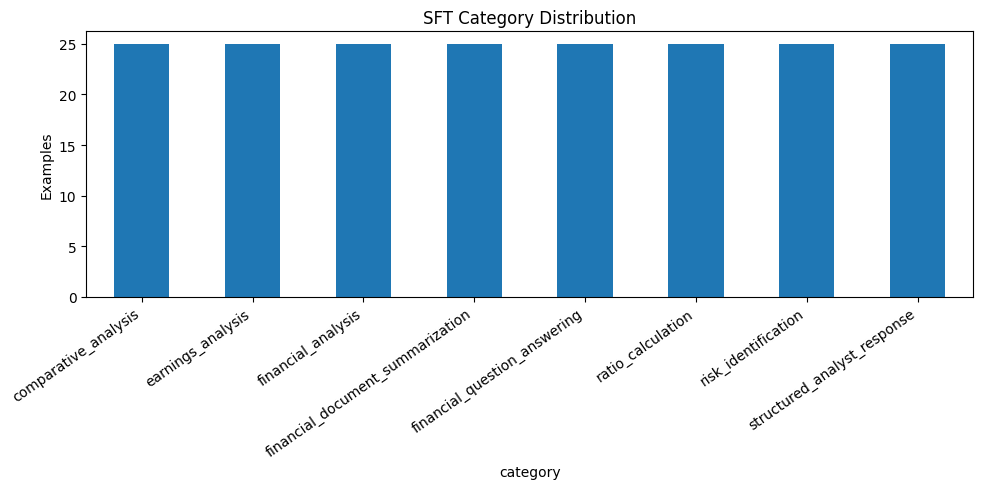

In [8]:
sft_df = sft_ds.to_pandas()

for col in ["category", "difficulty", "company", "source_document"]:
    print(f"\n--- {col} ---")
    print(sft_df[col].value_counts())

sft_df["instruction_chars"] = sft_df["instruction"].str.len()
sft_df["context_chars"] = sft_df["context"].str.len()
sft_df["response_chars"] = sft_df["response"].str.len()

print("\nLength statistics:")
display(
    sft_df[
        ["instruction_chars", "context_chars", "response_chars"]
    ].describe().round(1)
)

print("\nMissing values:")
display(sft_df.isna().sum().to_frame("missing"))

print("\nCategory distribution:")
plt.figure(figsize=(10, 5))
sft_df["category"].value_counts().sort_index().plot(kind="bar")
plt.ylabel("Examples")
plt.title("SFT Category Distribution")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


## 8. Create SFT train/evaluation split

The original dataset contains 200 examples. We create a deterministic 90/10 split.

The evaluation split is used during SFT training for validation loss. The independent benchmark suite created earlier remains reserved for the final evaluation notebook.


In [9]:
from datasets import ClassLabel

# Prepare category for stratified splitting
category_names = sorted(set(sft_ds["category"]))

sft_ds = sft_ds.cast_column(
    "category",
    ClassLabel(names=category_names)
)

# 90/10 stratified split
sft_split = sft_ds.train_test_split(
    test_size=0.10,
    seed=SEED,
    stratify_by_column="category",
)

sft_train = sft_split["train"]
sft_eval = sft_split["test"]

print(f"SFT train: {len(sft_train)}")
print(f"SFT eval: {len(sft_eval)}")

print("\nTrain categories:")
print(pd.Series(
    [sft_train.features["category"].int2str(x) for x in sft_train["category"]]
).value_counts().sort_index())

print("\nEval categories:")
print(pd.Series(
    [sft_eval.features["category"].int2str(x) for x in sft_eval["category"]]
).value_counts().sort_index())

Casting the dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

SFT train: 180
SFT eval: 20

Train categories:
comparative_analysis                23
earnings_analysis                   22
financial_analysis                  22
financial_document_summarization    23
financial_question_answering        23
ratio_calculation                   22
risk_identification                 23
structured_analyst_response         22
Name: count, dtype: int64

Eval categories:
comparative_analysis                2
earnings_analysis                   3
financial_analysis                  3
financial_document_summarization    2
financial_question_answering        2
ratio_calculation                   3
risk_identification                 2
structured_analyst_response         3
Name: count, dtype: int64


## 9. Load the base model and Checkpoint 1 adapter

We load the same Hugging Face base model selected in Notebook 2 and attach its Checkpoint 1 LoRA adapter.

This is the starting point for SFT.


In [10]:
from unsloth import FastLanguageModel
from peft import PeftModel
from unsloth.chat_templates import get_chat_template

gc.collect()
torch.cuda.empty_cache()

base_model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=BASE_MODEL,
    max_seq_length=CFG["max_seq_length"],
    dtype=None,
    load_in_4bit=CFG["load_in_4bit"],
)

tokenizer = get_chat_template(
    tokenizer,
    chat_template="mistral",   # or "chatml" — see note below
)

model = PeftModel.from_pretrained(
    base_model,
    str(CHECKPOINT_1_ADAPTER),
    is_trainable=True,
)

print("Loaded base model:", BASE_MODEL)
print("Loaded Checkpoint 1 adapter:", CHECKPOINT_1_ADAPTER)
print("Trainable parameters:")
model.print_trainable_parameters()

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

tokenizer.padding_side = "right"


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.9.10: Fast Mistral patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Loaded base model: mistralai/Mistral-7B-v0.3
Loaded Checkpoint 1 adapter: /content/FinSight_dapt_Checkpoint_1/models/mistral_7b/checkpoint_1_adapter
Trainable parameters:
trainable params: 41,943,040 || all params: 7,289,966,592 || trainable%: 0.5754


## 10. SFT training

The dataset already contains a `messages` field in chat format.

TRL's `SFTTrainer` will apply the model's chat template and train on the assistant response.

**Checkpoint 2** is saved as the continued LoRA adapter after SFT.


In [11]:
# ============================================================
# 10. SFT TRAINING: CHECKPOINT 1 -> CHECKPOINT 2
# ============================================================

import time
import torch
from trl import SFTConfig, SFTTrainer

# ------------------------------------------------------------
# GPU / precision
# ------------------------------------------------------------

print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("BF16 supported:", torch.cuda.is_bf16_supported())

# FP16 for broad Colab GPU compatibility (BF16 unreliable here).
BF16 = False
FP16 = torch.cuda.is_available()
print("BF16:", BF16, "| FP16:", FP16)

# ------------------------------------------------------------
# Checkpoint 2 output directory
# ------------------------------------------------------------

CHECKPOINT_2_DIR = WORK_DIR / "checkpoint_2_sft_adapter"
CHECKPOINT_2_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Apply chat template once, up front -> plain "text" column
# ------------------------------------------------------------
# The dataset has a `messages` field in chat format. We render it
# to text ourselves here (rather than relying on SFTTrainer's
# internal auto-detection of conversational datasets), which
# avoids template-application conflicts under Unsloth.

def to_text(example):
    return {
        "text": tokenizer.apply_chat_template(
            example["messages"],
            tokenize=False,
            add_generation_prompt=False,
        )
    }

sft_train = sft_train.map(to_text, remove_columns=sft_train.column_names)
sft_eval = sft_eval.map(to_text, remove_columns=sft_eval.column_names)

print("\nSample formatted training example:")
print("=" * 80)
print(sft_train[0]["text"])
print("=" * 80)

# ------------------------------------------------------------
# SFT configuration
# ------------------------------------------------------------

WARMUP_STEPS = 5  # transformers/TRL now recommend warmup_steps over warmup_ratio

sft_args = SFTConfig(
    output_dir=str(WORK_DIR / "sft_training"),

    # Training
    num_train_epochs=CFG["sft_epochs"],
    per_device_train_batch_size=CFG["sft_batch_size"],
    per_device_eval_batch_size=CFG["sft_batch_size"],
    gradient_accumulation_steps=CFG["sft_gradient_accumulation_steps"],

    # Optimization
    learning_rate=CFG["sft_learning_rate"],
    warmup_steps=WARMUP_STEPS,
    weight_decay=CFG["weight_decay"],
    max_grad_norm=CFG["max_grad_norm"],
    optim="adamw_8bit",

    # Logging / evaluation / saving
    logging_steps=CFG["logging_steps"],
    eval_strategy=CFG["eval_strategy"],
    save_strategy=CFG["save_strategy"],
    save_total_limit=1,

    # Precision
    bf16=BF16,
    fp16=FP16,

    # Reproducibility
    seed=SEED,
    report_to="none",

    # Sequence length + text field
    max_length=CFG["max_seq_length"],
    dataset_text_field="text",
)

# ------------------------------------------------------------
# Trainer
# ------------------------------------------------------------

sft_trainer = SFTTrainer(
    model=model,
    args=sft_args,
    train_dataset=sft_train,
    eval_dataset=sft_eval,
    processing_class=tokenizer,
)

# ------------------------------------------------------------
# Train
# ------------------------------------------------------------

print("\nStarting SFT training...")
print("Base model:", BASE_MODEL)
print("Checkpoint 1:", CHECKPOINT_1_ADAPTER)
print("Training examples:", len(sft_train))
print("Evaluation examples:", len(sft_eval))
print("Epochs:", CFG["sft_epochs"])
print("Learning rate:", CFG["sft_learning_rate"])
print("Sequence length:", CFG["max_seq_length"])

sft_start = time.time()
sft_train_result = sft_trainer.train()
sft_seconds = time.time() - sft_start

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("SFT TRAINING COMPLETE")
print("=" * 80)
print("Training time:", round(sft_seconds / 60, 2), "minutes")
if hasattr(sft_train_result, "training_loss"):
    print("Final training loss:", round(sft_train_result.training_loss, 4))
print("=" * 80)

CUDA available: True
GPU: Tesla T4
BF16 supported: False
BF16: False | FP16: True


Map:   0%|          | 0/180 [00:00<?, ? examples/s]

Map:   0%|          | 0/20 [00:00<?, ? examples/s]


Sample formatted training example:
<s>[INST] You are FinSight AI, a financial analyst assistant. Use only the supplied evidence, show calculations when relevant, distinguish reported facts from interpretation, and state limitations when evidence is insufficient. Summarize Summit Arc's Q2 2026 flow trends.

Evidence:
Q2 2026 report and earnings call. [/INST]Net new assets were $118B, up 40.5% year over year, with private markets and fixed income leading flows. Active-equity outflows moderated and institutional retention improved. The source does not establish that all AUM growth came from net new assets because market movements also affect AUM.</s>
Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/180 [00:00<?, ? examples/s]

...

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.

Starting SFT training...
Base model: mistralai/Mistral-7B-v0.3
Checkpoint 1: /content/FinSight_dapt_Checkpoint_1/models/mistral_7b/checkpoint_1_adapter
Training examples: 180
Evaluation examples: 20
Epochs: 2
Learning rate: 0.0001
Sequence length: 1024


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 180 | Num Epochs = 2 | Total steps = 46
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 8
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 8 x 1) = 8
 "-____-"     Trainable parameters = 41,943,040 of 7,289,966,592 (0.58% trained)
`use_return_dict` is deprecated! Use `return_dict` instead!
/usr/local/lib/python3.13/dist-packages/unsloth/import_fixes.py:3239: UserWarning: 'has_cuda' is deprecated, please use 'torch.backends.cuda.is_built()'
  return original(name)
/usr/local/lib/python3.13/dist-packages/unsloth/import_fixes.py:3239: UserWarning: 'has_cudnn' is deprecated, please use 'torch.backends.cudnn.is_available()'
  return original(name)
/usr/local/lib/python3.13/dist-packages/unsloth/import_fixes.py:3239: UserWarning: 'has_mps' is deprecated, please use 'torch.backends.mps.is_built()'
  return original(name)
/usr/local/lib/python3.13/dist-packages

Epoch,Training Loss,Validation Loss
1,1.095983,1.060513
2,0.855609,0.925682


Unsloth: Restored added_tokens_decoder metadata in /content/FinSight_post_training/sft_training/checkpoint-23/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/FinSight_post_training/sft_training/checkpoint-23.
Unsloth: Restored added_tokens_decoder metadata in /content/FinSight_post_training/sft_training/checkpoint-46/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/FinSight_post_training/sft_training/checkpoint-46.



SFT TRAINING COMPLETE
Training time: 6.51 minutes
Final training loss: 1.3539


## 11. Evaluate SFT and save Checkpoint 2

In [12]:
from transformers.utils.notebook import NotebookProgressCallback

sft_trainer.remove_callback(NotebookProgressCallback)

sft_metrics = sft_trainer.evaluate()


if "eval_loss" in sft_metrics:
    sft_metrics["eval_perplexity"] = math.exp(sft_metrics["eval_loss"])

sft_metrics["training_seconds"] = sft_seconds
sft_metrics["base_model"] = BASE_MODEL
sft_metrics["checkpoint_1_adapter"] = str(CHECKPOINT_1_ADAPTER)

print(json.dumps(sft_metrics, indent=2, default=float))

# Save the continued adapter and tokenizer.
sft_trainer.model.save_pretrained(CHECKPOINT_2_DIR)
tokenizer.save_pretrained(CHECKPOINT_2_DIR)

checkpoint_2_manifest = {
    "checkpoint": "checkpoint_2",
    "stage": "supervised_fine_tuning",
    "base_model": BASE_MODEL,
    "parent_checkpoint": "checkpoint_1",
    "parent_adapter": str(CHECKPOINT_1_ADAPTER),
    "adapter_path": str(CHECKPOINT_2_DIR),
    "sft_metrics": {k: float(v) if isinstance(v, (np.floating, np.integer)) else v for k, v in sft_metrics.items()},
}

(WORK_DIR / "checkpoint_2_manifest.json").write_text(
    json.dumps(checkpoint_2_manifest, indent=2, default=float)
)

print("\nCheckpoint 2 saved to:", CHECKPOINT_2_DIR)


{
  "eval_loss": 0.9256817102432251,
  "eval_runtime": 6.0596,
  "eval_samples_per_second": 3.301,
  "eval_steps_per_second": 3.301,
  "epoch": 2.0,
  "eval_perplexity": 2.5235880299089555,
  "training_seconds": 390.4659836292267,
  "base_model": "mistralai/Mistral-7B-v0.3",
  "checkpoint_1_adapter": "/content/FinSight_dapt_Checkpoint_1/models/mistral_7b/checkpoint_1_adapter"
}


Unsloth: Restored added_tokens_decoder metadata in /content/FinSight_post_training/checkpoint_2_sft_adapter/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/FinSight_post_training/checkpoint_2_sft_adapter.



Checkpoint 2 saved to: /content/FinSight_post_training/checkpoint_2_sft_adapter


## 12. Inspect SFT training curves

,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
3,1.095983,1.802368,0.000071,0.888889,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,1.000000,23,1.060513,7.0840,2.823,2.823,NaN,NaN,NaN,NaN,NaN
5,1.055083,1.801052,0.000061,1.088889,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,0.941561,3.731217,0.000049,1.311111,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,0.939273,2.197655,0.000037,1.533333,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,0.867236,1.710958,0.000024,1.755556,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,0.855609,1.863076,0.000012,1.977778,45,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,NaN,NaN,NaN,2.000000,46,0.925682,6.2629,3.193,3.193,NaN,NaN,NaN,NaN,NaN
11,NaN,NaN,NaN,2.000000,46,NaN,NaN,NaN,NaN,387.9878,0.928,0.119,2.167505e+15,1.353892
12,NaN,NaN,NaN,2.000000,46,0.925682,6.0596,3.301,3.301,NaN,NaN,NaN,NaN,NaN


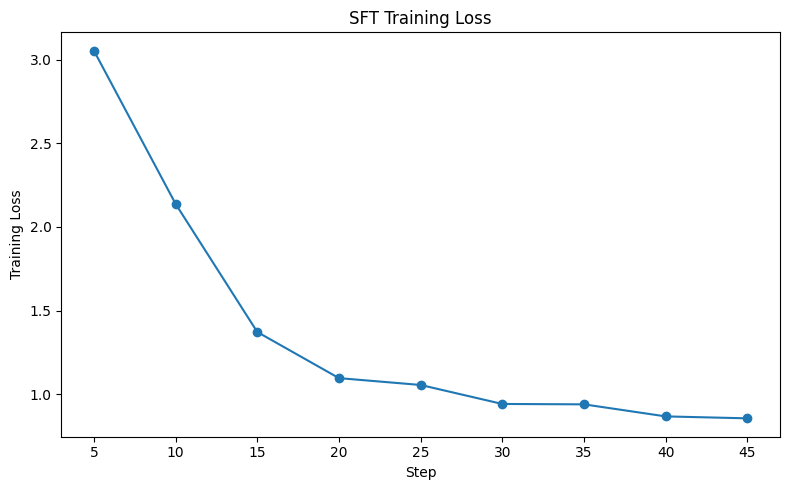

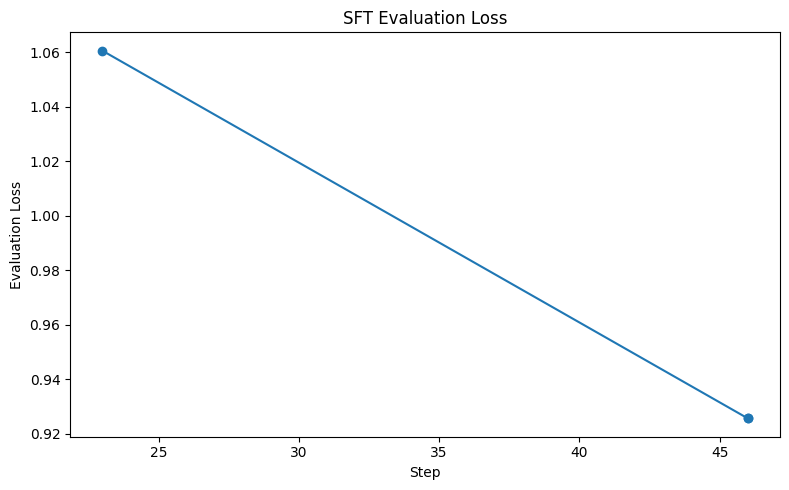

In [13]:
history_df = pd.DataFrame(sft_trainer.state.log_history)

display(history_df.tail(10))

if "loss" in history_df.columns:
    train_hist = history_df.dropna(subset=["loss"])
    if len(train_hist):
        plt.figure(figsize=(8, 5))
        plt.plot(train_hist["step"], train_hist["loss"], marker="o")
        plt.xlabel("Step")
        plt.ylabel("Training Loss")
        plt.title("SFT Training Loss")
        plt.tight_layout()
        plt.show()

if "eval_loss" in history_df.columns:
    eval_hist = history_df.dropna(subset=["eval_loss"])
    if len(eval_hist):
        plt.figure(figsize=(8, 5))
        plt.plot(eval_hist["step"], eval_hist["eval_loss"], marker="o")
        plt.xlabel("Step")
        plt.ylabel("Evaluation Loss")
        plt.title("SFT Evaluation Loss")
        plt.tight_layout()
        plt.show()


## 13. Free GPU memory before DPO

DPO starts from **Checkpoint 2**, so the SFT model is unloaded before the next training stage.


In [14]:
del sft_trainer
del model
del base_model
gc.collect()
torch.cuda.empty_cache()

print("GPU memory cleared for DPO.")


GPU memory cleared for DPO.


## 14. Load the DPO preference dataset

In [15]:
assert DPO_FILE.exists(), f"DPO dataset not found: {DPO_FILE}"

dpo_ds = load_dataset("json", data_files=str(DPO_FILE), split="train")

print(dpo_ds)
print("Rows:", len(dpo_ds))
print("Columns:", dpo_ds.column_names)
print(dpo_ds[0])


Generating train split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['id', 'category', 'difficulty', 'company', 'source_document', 'prompt', 'chosen', 'rejected', 'preference_reason'],
    num_rows: 100
})
Rows: 100
Columns: ['id', 'category', 'difficulty', 'company', 'source_document', 'prompt', 'chosen', 'rejected', 'preference_reason']
{'id': 'DPO-0043', 'category': 'earnings_analysis', 'difficulty': 'hard', 'company': 'Summit Arc Asset Management plc', 'source_document': 'summit_arc_asset_management_plc_earnings_call_q2_2026.pdf', 'prompt': 'What did Summit Arc say about active equity?\n\nEvidence:\nQ2 2026 call: modest active-equity outflows; institutional retention improved.', 'chosen': 'Management said active-equity outflows were modest in Q2 2026, while retention among larger institutional clients improved and several teams posted better relative performance.', 'rejected': "Management said active-equity outflows were modest in Q2 2026, while retention among larger institutional clients improved and several teams posted b

## 15. DPO dataset EDA

The preference dataset contains:
- `prompt`
- `chosen`
- `rejected`

We inspect category distribution and response lengths.

The rejected responses intentionally contain realistic failure modes that the preference objective should learn to avoid.


Category distribution:


,count
category,
comparative_analysis,12
earnings_analysis,13
financial_analysis,13
financial_document_summarization,12
financial_question_answering,13
ratio_calculation,13
risk_identification,12
structured_analyst_response,12



Difficulty distribution:


,count
difficulty,
medium,50
hard,37
easy,13



Length statistics:


,prompt_chars,chosen_chars,rejected_chars
count,100.0,100.0,100.0
mean,128.4,197.3,253.2
std,42.5,104.4,113.4
min,58.0,34.0,49.0
25%,94.8,111.0,176.2
50%,123.0,191.5,257.5
75%,154.0,270.2,343.2
max,268.0,455.0,455.0



Missing values:


,missing
prompt,0
chosen,0
rejected,0


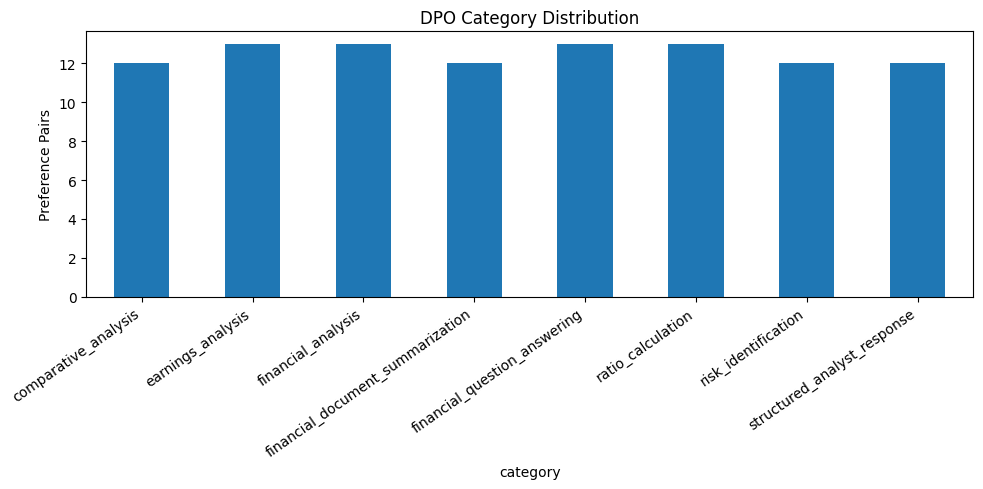

In [16]:
dpo_df = dpo_ds.to_pandas()

dpo_df["prompt_chars"] = dpo_df["prompt"].str.len()
dpo_df["chosen_chars"] = dpo_df["chosen"].str.len()
dpo_df["rejected_chars"] = dpo_df["rejected"].str.len()

print("Category distribution:")
display(dpo_df["category"].value_counts().sort_index())

print("\nDifficulty distribution:")
display(dpo_df["difficulty"].value_counts())

print("\nLength statistics:")
display(
    dpo_df[
        ["prompt_chars", "chosen_chars", "rejected_chars"]
    ].describe().round(1)
)

print("\nMissing values:")
display(dpo_df[["prompt", "chosen", "rejected"]].isna().sum().to_frame("missing"))

plt.figure(figsize=(10, 5))
dpo_df["category"].value_counts().sort_index().plot(kind="bar")
plt.ylabel("Preference Pairs")
plt.title("DPO Category Distribution")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


## 16. Create DPO train/evaluation split

We use an 80/20 split.

The DPO evaluation set is used for monitoring preference-training behavior. Final model quality should still be measured using the independent financial benchmark suite in Notebook 4.


In [17]:
from datasets import ClassLabel

# Get the unique category values to build the ClassLabel schema
categories = sorted(set(dpo_ds["category"]))
class_label = ClassLabel(names=categories)

dpo_ds = dpo_ds.cast_column("category", class_label)

dpo_split = dpo_ds.train_test_split(
    test_size=0.20,
    seed=SEED,
    stratify_by_column="category",
)

dpo_train = dpo_split["train"]
dpo_eval = dpo_split["test"]

print("DPO train:", len(dpo_train))
print("DPO eval:", len(dpo_eval))

Casting the dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

DPO train: 80
DPO eval: 20


## 17. Load Checkpoint 2 and prepare DPO

Checkpoint 2 is loaded as the starting adapter.

DPO then continues training that adapter rather than starting again from the original base model.


In [18]:
from peft import PeftModel
from unsloth import FastLanguageModel
from unsloth.chat_templates import get_chat_template

gc.collect()
torch.cuda.empty_cache()

base_model_dpo, tokenizer_dpo = FastLanguageModel.from_pretrained(
    model_name=BASE_MODEL,
    max_seq_length=CFG["max_seq_length"],
    dtype=None,
    load_in_4bit=CFG["load_in_4bit"],
)

tokenizer = get_chat_template(
    tokenizer,
    chat_template="mistral",   # or "chatml" — see note below
)

model_dpo = PeftModel.from_pretrained(
    base_model_dpo,
    str(CHECKPOINT_2_DIR),
    is_trainable=True,
)

if tokenizer_dpo.pad_token is None:
    tokenizer_dpo.pad_token = tokenizer_dpo.eos_token

tokenizer_dpo.padding_side = "right"

print("Loaded Checkpoint 2:", CHECKPOINT_2_DIR)
model_dpo.print_trainable_parameters()


==((====))==  Unsloth 2026.9.10: Fast Mistral patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Loaded Checkpoint 2: /content/FinSight_post_training/checkpoint_2_sft_adapter
trainable params: 41,943,040 || all params: 7,289,966,592 || trainable%: 0.5754


## 18. DPO training

DPO learns from:

`prompt + chosen response + rejected response`

The objective increases the relative preference for the chosen response while discouraging the rejected behavior.

For this portfolio experiment:
- DPO beta = 0.1
- one epoch
- lower learning rate than SFT


In [19]:
from trl import DPOConfig, DPOTrainer

CHECKPOINT_3_DIR = WORK_DIR / "checkpoint_3_dpo_adapter"
CHECKPOINT_3_DIR.mkdir(parents=True, exist_ok=True)

dpo_args = DPOConfig(
    output_dir=str(WORK_DIR / "dpo_training"),
    num_train_epochs=CFG["dpo_epochs"],
    per_device_train_batch_size=CFG["dpo_batch_size"],
    per_device_eval_batch_size=CFG["dpo_batch_size"],
    gradient_accumulation_steps=CFG["dpo_gradient_accumulation_steps"],
    learning_rate=CFG["dpo_learning_rate"],
    warmup_ratio=CFG["dpo_warmup_ratio"],
    beta=CFG["dpo_beta"],
    weight_decay=CFG["weight_decay"],
    logging_steps=CFG["logging_steps"],
    eval_strategy=CFG["eval_strategy"],
    save_strategy=CFG["save_strategy"],
    save_total_limit=1,
    bf16=BF16,
    fp16=FP16,
    optim="adamw_8bit",
    max_grad_norm=CFG["max_grad_norm"],
    report_to="none",
    seed=SEED,
    max_length=CFG["max_seq_length"],
    max_prompt_length=768,
)

dpo_trainer = DPOTrainer(
    model=model_dpo,
    ref_model=None,
    args=dpo_args,
    train_dataset=dpo_train,
    eval_dataset=dpo_eval,
    processing_class=tokenizer_dpo,
)

dpo_start = time.time()
dpo_train_result = dpo_trainer.train()
dpo_seconds = time.time() - dpo_start

print("DPO training complete.")
print("Training time:", round(dpo_seconds / 60, 2), "minutes")


warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Extracting prompt in train dataset (num_proc=2):   0%|          | 0/80 [00:00<?, ? examples/s]

Applying chat template to train dataset (num_proc=2):   0%|          | 0/80 [00:00<?, ? examples/s]

Tokenizing train dataset (num_proc=2):   0%|          | 0/80 [00:00<?, ? examples/s]

Extracting prompt in eval dataset (num_proc=2):   0%|          | 0/20 [00:00<?, ? examples/s]

...

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 80 | Num Epochs = 1 | Total steps = 10
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 8
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 8 x 1) = 8
 "-____-"     Trainable parameters = 41,943,040 of 7,289,966,592 (0.58% trained)


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.
Unsloth: Will smartly offload gradients to save VRAM!


Epoch,Training Loss,Validation Loss,Rewards/chosen,Rewards/rejected,Rewards/accuracies,Rewards/margins,Logps/chosen,Logps/rejected,Logits/chosen,Logits/rejected
1,0.168591,0.119888,-0.898484,-7.085598,0.950000,6.187114,-109.287979,-208.636719,-2.599588,-2.604928


Unsloth: Restored added_tokens_decoder metadata in /content/FinSight_post_training/dpo_training/checkpoint-10/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/FinSight_post_training/dpo_training/checkpoint-10.


DPO training complete.
Training time: 2.85 minutes


## 19. Evaluate DPO and save Checkpoint 3

In [21]:
from transformers.utils.notebook import NotebookProgressCallback

dpo_trainer.remove_callback(NotebookProgressCallback)

dpo_metrics = dpo_trainer.evaluate()


dpo_metrics["training_seconds"] = dpo_seconds
dpo_metrics["base_model"] = BASE_MODEL
dpo_metrics["parent_checkpoint"] = "checkpoint_2"

print(json.dumps(dpo_metrics, indent=2, default=float))

dpo_trainer.model.save_pretrained(CHECKPOINT_3_DIR)
tokenizer_dpo.save_pretrained(CHECKPOINT_3_DIR)

checkpoint_3_manifest = {
    "checkpoint": "checkpoint_3",
    "stage": "direct_preference_optimization",
    "base_model": BASE_MODEL,
    "parent_checkpoint": "checkpoint_2",
    "parent_adapter": str(CHECKPOINT_2_DIR),
    "adapter_path": str(CHECKPOINT_3_DIR),
    "dpo_config": {
        "beta": CFG["dpo_beta"],
        "epochs": CFG["dpo_epochs"],
        "learning_rate": CFG["dpo_learning_rate"],
    },
    "dpo_metrics": {
        k: float(v) if isinstance(v, (np.floating, np.integer)) else v
        for k, v in dpo_metrics.items()
    },
}

(WORK_DIR / "checkpoint_3_manifest.json").write_text(
    json.dumps(checkpoint_3_manifest, indent=2, default=float)
)

print("\nCheckpoint 3 saved to:", CHECKPOINT_3_DIR)


{
  "eval_loss": 0.11988826096057892,
  "eval_runtime": 17.9879,
  "eval_samples_per_second": 1.112,
  "eval_steps_per_second": 1.112,
  "eval_rewards/chosen": -0.8984844088554382,
  "eval_rewards/rejected": -7.085597991943359,
  "eval_rewards/accuracies": 0.949999988079071,
  "eval_rewards/margins": 6.1871137619018555,
  "eval_logps/chosen": -109.28797912597656,
  "eval_logps/rejected": -208.63671875,
  "eval_logits/chosen": -2.599588394165039,
  "eval_logits/rejected": -2.604928493499756,
  "epoch": 1.0,
  "training_seconds": 170.94495344161987,
  "base_model": "mistralai/Mistral-7B-v0.3",
  "parent_checkpoint": "checkpoint_2"
}


Unsloth: Restored added_tokens_decoder metadata in /content/FinSight_post_training/checkpoint_3_dpo_adapter/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/FinSight_post_training/checkpoint_3_dpo_adapter.



Checkpoint 3 saved to: /content/FinSight_post_training/checkpoint_3_dpo_adapter


## 20. DPO training curves

,loss,grad_norm,learning_rate,rewards/chosen,rewards/rejected,rewards/accuracies,rewards/margins,logps/chosen,logps/rejected,logits/chosen,...,eval_rewards/margins,eval_logps/chosen,eval_logps/rejected,eval_logits/chosen,eval_logits/rejected,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,0.430700,2.351243,0.000033,4.584851,3.483173,0.800,1.101678,-73.732101,-127.471436,-3.076016,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.168591,2.262900,0.000011,1.703775,-2.752930,0.875,4.456704,-110.474037,-188.498627,-2.653286,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,6.187114,-109.287979,-208.636719,-2.599588,-2.604928,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,166.7581,0.48,0.06,0.0,0.299645
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,6.187114,-109.287979,-208.636719,-2.599588,-2.604928,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,6.187114,-109.287979,-208.636719,-2.599588,-2.604928,NaN,NaN,NaN,NaN,NaN


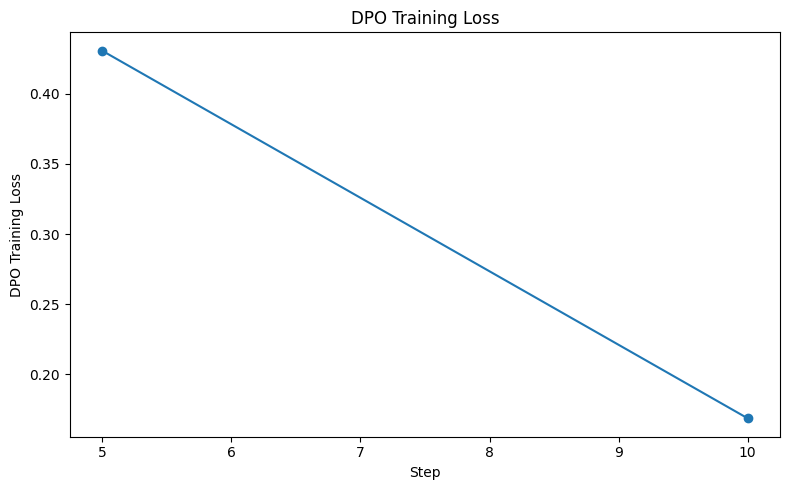

In [22]:
dpo_history_df = pd.DataFrame(dpo_trainer.state.log_history)
display(dpo_history_df.tail(15))

if "loss" in dpo_history_df.columns:
    dpo_train_hist = dpo_history_df.dropna(subset=["loss"])
    if len(dpo_train_hist):
        plt.figure(figsize=(8, 5))
        plt.plot(dpo_train_hist["step"], dpo_train_hist["loss"], marker="o")
        plt.xlabel("Step")
        plt.ylabel("DPO Training Loss")
        plt.title("DPO Training Loss")
        plt.tight_layout()
        plt.show()


## 21. Generation sanity check

This is a qualitative check, not the final benchmark.

We generate answers from **Checkpoint 3** for a few held-out SFT prompts and inspect whether the model:
- uses the supplied evidence
- performs calculations correctly
- avoids unsupported claims
- produces a structured financial response


In [28]:
from unsloth.chat_templates import get_chat_template
tokenizer_dpo = get_chat_template(tokenizer_dpo, chat_template="mistral")

In [29]:
# Use the final DPO-trained model already in memory.
from transformers import TextStreamer

def generate_answer(prompt, max_new_tokens=180):
    messages = [
        {
            "role": "system",
            "content": (
                "You are FinSight AI, a financial analyst assistant. "
                "Use only the supplied evidence, show calculations when relevant, "
                "distinguish reported facts from interpretation, and state limitations "
                "when evidence is insufficient."
            ),
        },
        {"role": "user", "content": prompt},
    ]

    inputs = tokenizer_dpo.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
    ).to(model_dpo.device)

    with torch.inference_mode():
        outputs = model_dpo.generate(
            input_ids=inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            temperature=None,
            pad_token_id=tokenizer_dpo.eos_token_id,
        )

    generated = outputs[0][inputs.shape[-1]:]
    return tokenizer_dpo.decode(generated, skip_special_tokens=True)

# Select five deterministic examples from the ORIGINAL SFT eval split
# (sft_eval was overwritten to a text-only column earlier for training;
# sft_split["test"] still holds the untouched fields).
sft_eval_raw = sft_split["test"]
sanity_examples = [sft_eval_raw[i] for i in range(min(5, len(sft_eval_raw)))]

for i, ex in enumerate(sanity_examples, start=1):
    prompt = ex["instruction"] + "\n\nEvidence:\n" + ex["context"]
    print("=" * 90)
    print(f"Example {i} | Category: {ex['category']}")
    print("PROMPT:")
    print(prompt)
    print("\nMODEL RESPONSE:")
    print(generate_answer(prompt))
    print("\nREFERENCE RESPONSE:")
    print(ex["response"])

The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Example 1 | Category: 1
PROMPT:
Summarize the key earnings messages from Summit Arc's Q2 2026 call.

Evidence:
Q2 2026 call: revenue $1.02B; net income $0.27B; AUM $10.4T; full-year planning ranges 2%-4% net inflows and 39%-41% margin.

MODEL RESPONSE:


Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Revenue was $1.02B, up 12.1%; net income was $0.27B, up 16.1%; AUM was $10.4T; active equity outflows improved to $10B from $16B; full-year planning ranges are 2%-4% net new assets and 39%-41% margin.

REFERENCE RESPONSE:
Summit Arc reported $1.02B of revenue, $0.27B of net income, and $10.4T of AUM. Private markets and fixed income led flows, while active-equity outflows moderated. Management maintained a full-year planning range of 2%-4% organic net inflows and 39%-41% adjusted operating margin, with research summarization and internal knowledge retrieval as the main generative-AI pilots.
Example 2 | Category: 7
PROMPT:
Draft a source-grounded risk brief.

Evidence:
Q2 2026 financial report and management commentary.

MODEL RESPONSE:


Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Meridian Crest payment volume grew 18.1%, fraud losses 8.4 basis points, and active merchants 7.1M. Fraud loss rate was 8.4 bps, compared with 7.9 bps a year earlier.

REFERENCE RESPONSE:
Primary risk: Office CRE credit quality. | Evidence: Management calls it the primary balance-sheet sensitivity and says monitoring frequency increased. | Secondary risks: funding costs, model/data, cyber and regulatory risk. | Limitation: The supplied report does not provide a complete stress-loss estimate for office CRE.
Example 3 | Category: 5
PROMPT:
Calculate FinoraPay's 2025 net margin.

Evidence:
FY2025 revenue $2.96B; net income $0.41B.

MODEL RESPONSE:


Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Net margin = ($0.41B / $2.96B) × 100 = 13.8% approximately.

REFERENCE RESPONSE:
Net margin = $0.41B / $2.96B × 100 = 13.9% approximately.
Example 4 | Category: 3
PROMPT:
Summarize the fraud-management message.

Evidence:
Q2 2026 call.

MODEL RESPONSE:


Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Fraud loss rate was 6.1 bps, down from 7.0 bps a year earlier. Meridian Crest reported $101M in fraud loss in Q2 2026.

REFERENCE RESPONSE:
Fraud loss rate improved to 5.8 bps from 6.5 bps. Management attributes the trend to better data coverage and model quality but continues to monitor drift and adversarial behavior.
Example 5 | Category: 6
PROMPT:
Why is fraud-model drift a risk despite recent fraud improvement?

Evidence:
Q2 2026 call: fraud dynamic; monitor drift and adversarial behavior.

MODEL RESPONSE:
Fraud models can degrade over time if the distribution of fraud changes, adversarial actors adjust their behavior, or data quality deteriorates. The company monitors drift, adversarial behavior, and data quality.

REFERENCE RESPONSE:
Fraud patterns can change and adversarial behavior can evolve. Management explicitly says fraud is dynamic, so a recent improvement in loss rates does not eliminate model-drift risk.


## 22. Final checkpoint summary

At the end of Notebook 3:

```text
Checkpoint 1
   ↓
Domain-Adaptive Continued Pretraining
   ↓
SFT
   ↓
Checkpoint 2
   ↓
DPO
   ↓
Checkpoint 3
```

The saved adapters can be used in the next notebook for independent financial benchmark evaluation.

### Expected outputs

```text
/content/finsight_post_training/
├── checkpoint_2_sft_adapter/
├── checkpoint_3_dpo_adapter/
├── checkpoint_2_manifest.json
├── checkpoint_3_manifest.json
├── sft_training/
└── dpo_training/
```

**Checkpoint 3 is the final post-trained FinSight AI adapter from this notebook.**


In [30]:
print("=== FinSight AI Notebook 3 Complete ===")
print("Base model:", BASE_MODEL)
print("Checkpoint 1:", CHECKPOINT_1_ADAPTER)
print("Checkpoint 2:", CHECKPOINT_2_DIR)
print("Checkpoint 3:", CHECKPOINT_3_DIR)

print("\nCheckpoint 2 manifest:")
print(json.dumps(checkpoint_2_manifest, indent=2, default=float))

print("\nCheckpoint 3 manifest:")
print(json.dumps(checkpoint_3_manifest, indent=2, default=float))


=== FinSight AI Notebook 3 Complete ===
Base model: mistralai/Mistral-7B-v0.3
Checkpoint 1: /content/FinSight_dapt_Checkpoint_1/models/mistral_7b/checkpoint_1_adapter
Checkpoint 2: /content/FinSight_post_training/checkpoint_2_sft_adapter
Checkpoint 3: /content/FinSight_post_training/checkpoint_3_dpo_adapter

Checkpoint 2 manifest:
{
  "checkpoint": "checkpoint_2",
  "stage": "supervised_fine_tuning",
  "base_model": "mistralai/Mistral-7B-v0.3",
  "parent_checkpoint": "checkpoint_1",
  "parent_adapter": "/content/FinSight_dapt_Checkpoint_1/models/mistral_7b/checkpoint_1_adapter",
  "adapter_path": "/content/FinSight_post_training/checkpoint_2_sft_adapter",
  "sft_metrics": {
    "eval_loss": 0.9256817102432251,
    "eval_runtime": 6.0596,
    "eval_samples_per_second": 3.301,
    "eval_steps_per_second": 3.301,
    "epoch": 2.0,
    "eval_perplexity": 2.5235880299089555,
    "training_seconds": 390.4659836292267,
    "base_model": "mistralai/Mistral-7B-v0.3",
    "checkpoint_1_adapter":